# 3.0 - Supervised Modeling: Churn Prediction
**Week 3** | `src/modeling/train.py`

## Target definition (leakage-safe)
The brief's example is *"no purchase in the last 60 days"*. If we computed that from the same data as the Recency feature, the label would be a deterministic function of an input (**target leakage**). Instead we use a **time-based snapshot**:

* Features: orders **before** `2025-10-31`
* Label `churned = 1`: **no order in the 60 days after** the snapshot

This is exactly the production question: *given what we know today, who will not buy again?*

In [1]:
import sys, warnings
sys.path.append("..")
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from src import config, features as F
sns.set_theme(style="whitegrid", palette="deep")
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 30)
def save(name):
    config.FIGURES_DIR.mkdir(parents=True, exist_ok=True)
    plt.savefig(config.FIGURES_DIR / name, dpi=140, bbox_inches="tight")
import joblib
from sklearn.metrics import (classification_report, confusion_matrix, roc_curve, precision_recall_curve, roc_auc_score)
from sklearn.inspection import permutation_importance
from src.modeling import train as T
tx = pd.read_csv(config.DATA_INTERIM / 'transactions_clean.csv', parse_dates=['order_date'])
customers = pd.read_csv(config.DATA_RAW / 'customers.csv', parse_dates=['signup_date'])
table = F.assemble_model_table(tx, customers)
print(table.shape, '| churn rate:', round(table.churned.mean(), 3))

(4913, 20) | churn rate: 0.668


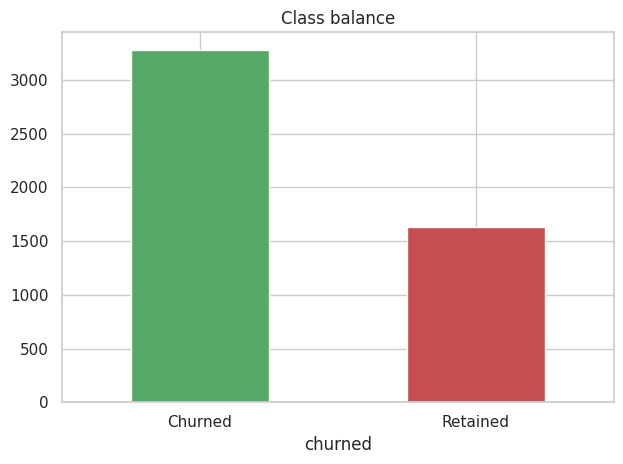

In [2]:
ax = table.churned.value_counts().rename({0:'Retained', 1:'Churned'}).plot.bar(color=['C2','C3'], title='Class balance'); plt.xticks(rotation=0)
plt.tight_layout(); save('09_class_balance.png'); plt.show()

## 1. Candidate models
Logistic Regression and Random Forest, each with **class weights** or **SMOTE**. SMOTE sits *inside* an `imblearn` pipeline so synthetic samples are generated only on training folds - never on validation folds (otherwise CV scores are inflated). Selection metric = mean 5-fold CV ROC-AUC on the training set; the 20 % hold-out test set is touched only once for reporting.

In [3]:
results, fitted, X_te, y_te = T.run_experiment(table)
results.round(4)

,model,cv_roc_auc_mean,cv_roc_auc_std,precision,recall,f1,roc_auc,pr_auc
0,rf_class_weight,0.9127,0.0053,0.9182,0.8384,0.8765,0.9139,0.9603
1,logreg_class_weight,0.9126,0.0061,0.9233,0.8079,0.8618,0.9120,0.9592
2,logreg_smote,0.9116,0.0060,0.9223,0.8140,0.8648,0.9104,0.9585
3,rf_smote,0.9115,0.0061,0.9041,0.8476,0.8749,0.9100,0.9587


In [4]:
best_name = results.iloc[0].model; best = fitted[best_name]
m = T.evaluate(best, X_te, y_te)
T.save_model(best, 'churn_model', m)
results.to_csv(config.DATA_PROCESSED / 'model_comparison.csv', index=False)
print('Selected:', best_name); print({k: round(v, 4) for k, v in m.items()})
print('\nROC-AUC >= 0.75 target:', 'PASS' if m['roc_auc'] >= .75 else 'FAIL')

Selected: rf_class_weight
{'precision': 0.9182, 'recall': 0.8384, 'f1': 0.8765, 'roc_auc': 0.9139, 'pr_auc': 0.9603}

ROC-AUC >= 0.75 target: PASS


## 2. Evaluation

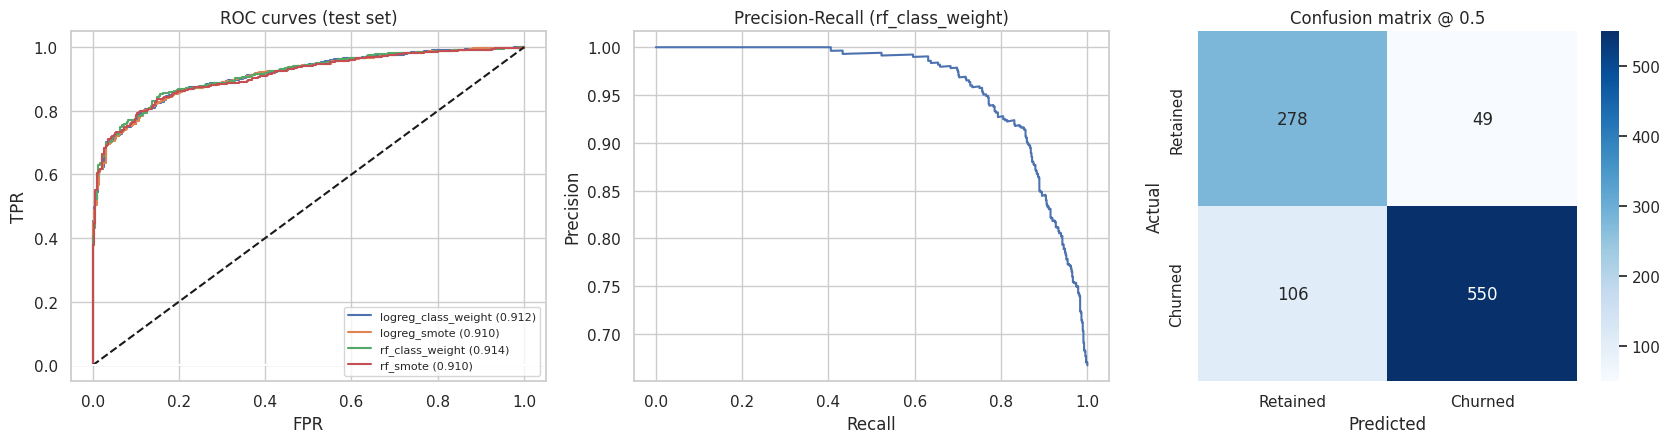

              precision    recall  f1-score   support

    Retained       0.72      0.85      0.78       327
     Churned       0.92      0.84      0.88       656

    accuracy                           0.84       983
   macro avg       0.82      0.84      0.83       983
weighted avg       0.85      0.84      0.85       983



In [5]:
fig, ax = plt.subplots(1, 3, figsize=(17, 4.6))
for name, mdl in fitted.items():
    p = mdl.predict_proba(X_te)[:, 1]; fpr, tpr, _ = roc_curve(y_te, p)
    ax[0].plot(fpr, tpr, label=f'{name} ({roc_auc_score(y_te, p):.3f})')
ax[0].plot([0,1],[0,1],'k--'); ax[0].axhline(0, c='w'); ax[0].set_title('ROC curves (test set)'); ax[0].set_xlabel('FPR'); ax[0].set_ylabel('TPR'); ax[0].legend(fontsize=8)
p = best.predict_proba(X_te)[:, 1]; pr, rc, _ = precision_recall_curve(y_te, p)
ax[1].plot(rc, pr); ax[1].set_title(f'Precision-Recall ({best_name})'); ax[1].set_xlabel('Recall'); ax[1].set_ylabel('Precision')
cm = confusion_matrix(y_te, (p >= .5).astype(int))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=ax[2], xticklabels=['Retained','Churned'], yticklabels=['Retained','Churned']); ax[2].set_title('Confusion matrix @ 0.5'); ax[2].set_xlabel('Predicted'); ax[2].set_ylabel('Actual')
plt.tight_layout(); save('10_model_evaluation.png'); plt.show()
print(classification_report(y_te, (p >= .5).astype(int), target_names=['Retained','Churned']))

### Honest sanity check - is the score inflated by customers who already left?
Many churners lapsed long ago (e.g. 300+ days of silence); predicting them is easy. The business cares most about **still-active** customers, so we also report AUC on customers who ordered in the last 180 days.

In [6]:
mask = (X_te.recency_days <= 180).to_numpy()
print('Active customers in test set:', int(mask.sum()), '| churn rate among them:', round(float(y_te[mask].mean()), 3))
print('ROC-AUC (all customers)        :', round(roc_auc_score(y_te, p), 4))
print('ROC-AUC (active, <=180d silent):', round(roc_auc_score(y_te[mask], p[mask]), 4))

Active customers in test set: 596 | churn rate among them: 0.453
ROC-AUC (all customers)        : 0.9139
ROC-AUC (active, <=180d silent): 0.7972


## 3. Why does the model predict churn? (feature importance)

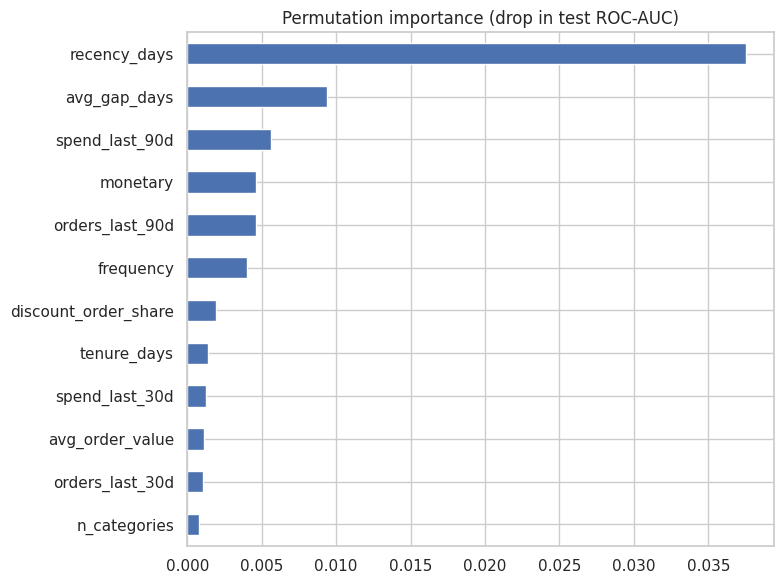

recency_days            0.0375
avg_gap_days            0.0094
spend_last_90d          0.0057
monetary                0.0046
orders_last_90d         0.0046
frequency               0.0040
discount_order_share    0.0020
tenure_days             0.0014
dtype: float64

In [7]:
pi = permutation_importance(best, X_te, y_te, scoring='roc_auc', n_repeats=8, random_state=config.RANDOM_STATE, n_jobs=1)
imp = pd.Series(pi.importances_mean, index=X_te.columns).sort_values()
fig, ax = plt.subplots(figsize=(8, 6)); imp.tail(12).plot.barh(ax=ax, color='C0'); ax.set_title('Permutation importance (drop in test ROC-AUC)')
plt.tight_layout(); save('11_feature_importance.png'); plt.show()
imp.sort_values(ascending=False).head(8).round(4)

## 4. Choosing a decision threshold
At 0.5 the model is balanced; but a retention team may prefer to **catch more churners (Recall)** and accept more false alarms, since a missed churner costs a customer while a false alarm costs one discount email.

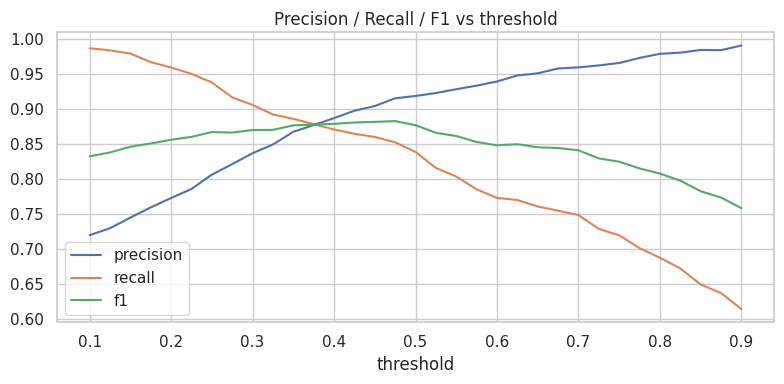

,threshold,precision,recall,f1
0,0.1,0.720,0.986,0.832
4,0.2,0.773,0.959,0.856
8,0.3,0.837,0.905,0.870
12,0.4,0.887,0.870,0.878
16,0.5,0.918,0.838,0.876
20,0.6,0.939,0.773,0.848
24,0.7,0.959,0.748,0.841
28,0.8,0.978,0.688,0.808
32,0.9,0.990,0.614,0.758


In [8]:
ths = np.linspace(.1, .9, 33)
rows = [dict(threshold=t, **{k: v for k, v in T.evaluate(best, X_te, y_te, t).items() if k in ('precision','recall','f1')}) for t in ths]
th = pd.DataFrame(rows)
ax = th.set_index('threshold')[['precision','recall','f1']].plot(figsize=(8, 4), title='Precision / Recall / F1 vs threshold'); plt.tight_layout(); save('12_threshold_tradeoff.png'); plt.show()
th.iloc[::4].round(3)

## Takeaways
* Both model families exceed the **ROC-AUC >= 0.75** requirement; class-weighting and SMOTE perform alike here, so we choose the simpler class-weight variant.
* Recency-related behaviour (silence relative to the customer's normal purchase gap) dominates importance - intuitive and actionable.
* Report the active-customer AUC alongside the headline AUC to avoid over-claiming.

**Next:** score the live customer base and build the BI dashboard (4.0).